# Modal-Decomposition · 6 分钟答辩演示

- 环境：仓库根目录、`.venv`（Python 3.10），全程 CPU，不联网；
- 信号：300 点合成信号（两个正弦 + 周期性冲击），任何机器 1 秒内出结果；
- 第一格把 `src/` 放到 `sys.path` 最前面，跑的就是仓库里提交的 0.5.0 源码。


## 0　导入与版本

一行导入背后是 15 个算法、5 层结构。


In [15]:
import pathlib
import sys

# 从当前目录向上找仓库根（含 src/Modal_Decomposition 的那一层），导入提交的 0.5.0 源码
root = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "src" / "Modal_Decomposition").is_dir())
sys.path.insert(0, str(root / "src"))

import warnings

import numpy as np
import Modal_Decomposition as md

warnings.filterwarnings("ignore")

print("版本:", md.__version__, "| 许可证:", md.__license__)
print("算法:", len([n for n in dir(md.Function) if not n.startswith("_")]), "个入口函数")


版本: 0.5.0 | 许可证: Apache 2.0
算法: 15 个入口函数


## 1　两个入口，一条实现

`Function.EMD(S)` 与 `Class.EMD().decompose(S)` 走同一份实现，结果必须逐位相同。


In [16]:
T = np.arange(0, 0.75, 1 / 400)
S = np.sin(8 * np.pi * T) + 0.5 * np.cos(240 * np.pi * T)
S[(T % 0.25 > 0.11) & (T % 0.25 < 0.12)] += 1.0
print("信号:", S.size, "点")

md.set_seed(42)
a = md.Function.EMD(S)                 # 函数式入口
b = md.Class.EMD().decompose(S)        # 类式入口
print("逐点相同:", np.array_equal(a.IMFs, b.IMFs), "| 模态数:", a.n_imfs)


信号: 300 点
逐点相同: True | 模态数: 5


## 2　统一返回结构

不管哪个方法，拿到的都是同一个 `DecompositionResult`：模态、残差、诊断信息、参数快照。


In [17]:
print("类型:", type(a).__name__)
print("字段:", list(a.__dataclass_fields__))
print("IMFs:", a.IMFs.shape, "| 残差:", a.Res.shape)
print("参数快照:", len(a.config.to_dict()), "个字段")

for name in ("SSA", "VMD"):            # 这两个方法本来就没有残差概念
    r = getattr(md.Function, name)(S)
    print(f"{name}: 模态 {r.n_imfs}，残差 {r.Res}")


类型: DecompositionResult
字段: ['IMFs', 'Res', 'info', 'config']
IMFs: (5, 300) | 残差: (300,)
参数快照: 15 个字段
SSA: 模态 100，残差 None
VMD: 模态 2，残差 None


## 3　换方法只改一个名字

同一段信号、同一个调用形状，四个方法并列。


In [18]:
import time

for name, kw in [("EMD", {}), ("EEMD", {"num_imf": 3, "M": 8}),
                 ("EWT", {"num_imfs": 4}), ("VMD", {"num_imf": 3})]:
    md.set_seed(42)
    t0 = time.perf_counter()
    r = getattr(md.Function, name)(S, **kw)
    ms = 1000 * (time.perf_counter() - t0)
    res = "—" if r.Res is None else f"{r.Res.shape[0]} 点"
    print(f"{name:<5} 模态 {r.n_imfs:>2}   {ms:7.1f} ms   残差 {res}")


EMD   模态  5       6.0 ms   残差 300 点
EEMD  模态  4      20.3 ms   残差 300 点
EWT   模态  4       0.9 ms   残差 300 点
VMD   模态  3       4.5 ms   残差 —


## 4　画出来

原始信号 + 模态 + 残差；换成别的方法，这段绘图代码一个字不用改。


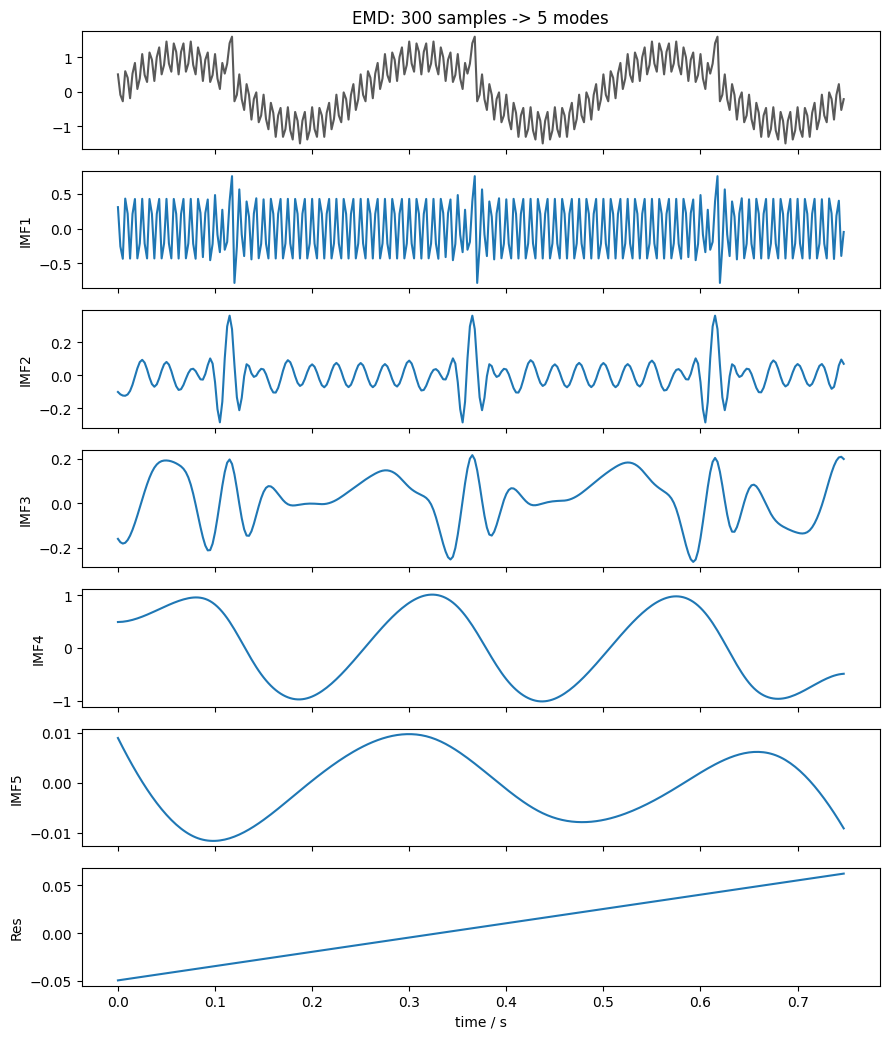

In [19]:
import matplotlib.pyplot as plt

md.set_seed(42)
res = md.Function.EMD(S)
n = res.n_imfs

fig, axes = plt.subplots(n + 2, 1, figsize=(9, 1.5 * (n + 2)), sharex=True)
axes[0].plot(T, S, color="0.35")
axes[0].set_title(f"EMD: {len(T)} samples -> {n} modes")
for i in range(n):
    axes[i + 1].plot(T, res.IMFs[i])
    axes[i + 1].set_ylabel(f"IMF{i + 1}")
axes[-1].plot(T, res.Res)
axes[-1].set_ylabel("Res")
axes[-1].set_xlabel("time / s")
fig.tight_layout()
plt.show()
